# Experiment 039 (W15): probe erosion across model scales

This notebook reuses the stored MC-SFT probe predictions at 0.5B, 1.5B, 3B and 7B.
It separates the total base-to-p32 change from the extra p8-to-p32 exposure, then checks
subjects, repeated item changes and answer choice movement. No model is loaded and no new
evaluation is run.


In [13]:
# load stored probe rows for every scale
import itertools
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("repository root containing config.py was not found")
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "039_1"
FIG.mkdir(parents=True, exist_ok=True)

EXPOSURES = {"p2": 2, "p8": 8, "p32": 32}
SEEDS = [0, 1, 2]
SCALES = ["0.5B", "1.5B", "3B", "7B"]
GROUPS = ["overall", "easy", "medium", "hard"]
TIER = {subject: tier for tier, subjects in TIERS.items() for subject in subjects}
TIER_COLORS = {"overall": "#4C78A8", "easy": "#59A14F", "medium": "#F28E2B", "hard": "#E15759"}

SCALE_PATHS = {
    "0.5B": {
        "base": "base_evals/007_p2_COLAB_FULL_B05",
        "p2": "007_p2_COLAB_FULL_B05_sft_only_seed{seed}",
        "p8": "007_p8_COLAB_FULL_B05_sft_only_seed{seed}",
        "p32": "007_p32_COLAB_FULL_B05_sft_only_seed{seed}",
    },
    "1.5B": {
        "base": "base_evals/010_p2_COLAB_FULL_B15",
        "p2": "010_p2_COLAB_FULL_B15_sft_only_seed{seed}",
        "p8": "010_p8_COLAB_FULL_B15_sft_only_seed{seed}",
        "p32": "010_p32_COLAB_FULL_B15_sft_only_seed{seed}",
    },
    "3B": {
        "base": "base_evals/007_p2_COLAB_FULL_B3",
        "p2": "007_p2_COLAB_FULL_B3_sft_only_seed{seed}",
        "p8": "007_p8_COLAB_FULL_B3_sft_only_seed{seed}",
        "p32": "007_p32_COLAB_FULL_B3_sft_only_seed{seed}",
    },
    "7B": {
        "base": "base_evals/025_p2_COLAB_FULL_B7",
        "p2": "025_p2_COLAB_FULL_B7_sft_only_seed{seed}",
        "p8": "014_p8_COLAB_FULL_B7_sft_only_seed{seed}",
        "p32": "025_p32_COLAB_FULL_B7_sft_only_seed{seed}",
    },
}


def read_rows(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


def selected(rows, group):
    if group == "overall":
        return rows
    return [row for row in rows if TIER[row["subject"]] == group]


def accuracy(rows, group="overall"):
    return float(np.mean([bool(row["correct"]) for row in selected(rows, group)]))


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")


data = {}
for scale, paths in SCALE_PATHS.items():
    base_raw = read_rows(RES / paths["base"] / "base_logprob_preds.jsonl")
    data[scale] = {"base": None, "p2": {}, "p8": {}, "p32": {}}
    for exposure in EXPOSURES:
        for seed in SEEDS:
            path = RES / paths[exposure].format(seed=seed) / "sft_logprob_preds.jsonl"
            base_rows, rows = align_pred_rows(base_raw, read_rows(path))
            assert len(base_rows) == len(rows) == 1884
            if data[scale]["base"] is None:
                data[scale]["base"] = base_rows
            base_keys = [(row["subject"], row["gold"]) for row in data[scale]["base"]]
            assert base_keys == [(row["subject"], row["gold"]) for row in base_rows]
            data[scale][exposure][seed] = rows

print("loaded", len(SCALES), "scales and", len(SCALES) * len(EXPOSURES) * len(SEEDS), "trained endpoints")


loaded 4 scales and 36 trained endpoints


## Exposure pattern


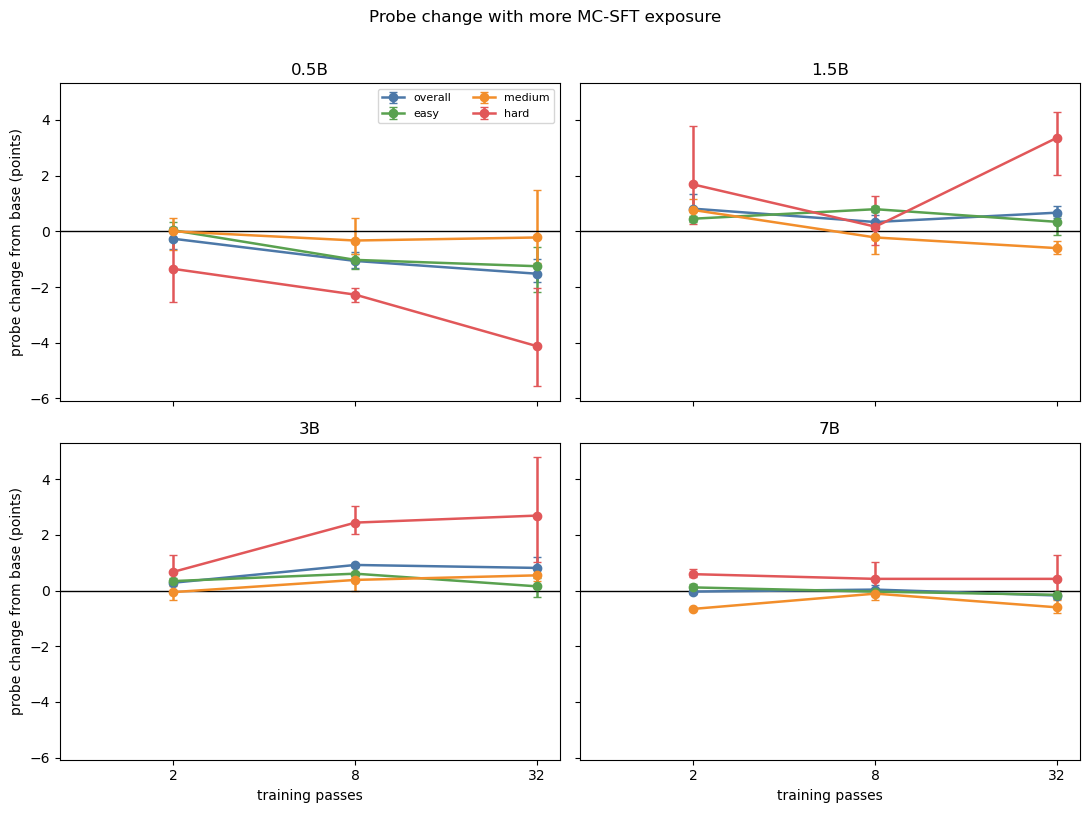

group         easy  hard  medium  overall
scale passes                             
0.5B  2       0.04 -1.35    0.00    -0.27
      8      -1.02 -2.27   -0.33    -1.06
      32     -1.25 -4.12   -0.22    -1.52
1.5B  2       0.46  1.68    0.77     0.81
      8       0.80  0.17   -0.22     0.34
      32      0.34  3.37   -0.60     0.67
3B    2       0.34  0.67   -0.05     0.28
      8       0.61  2.44    0.38     0.92
      32      0.15  2.69    0.55     0.81
7B    2       0.11  0.59   -0.66    -0.04
      8      -0.04  0.42   -0.11     0.04
      32     -0.15  0.42   -0.60    -0.18

In [14]:
exposure_rows = []
for scale in SCALES:
    for exposure, passes in EXPOSURES.items():
        for seed in SEEDS:
            for group in GROUPS:
                value = accuracy(data[scale][exposure][seed], group)
                exposure_rows.append({
                    "scale": scale,
                    "exposure": exposure,
                    "passes": passes,
                    "seed": seed,
                    "group": group,
                    "accuracy": value,
                    "delta_from_base": value - accuracy(data[scale]["base"], group),
                })

exposure_df = pd.DataFrame(exposure_rows)
exposure_summary = (exposure_df.groupby(["scale", "passes", "group"], sort=False)["delta_from_base"]
                    .agg(["mean", "min", "max"]).reset_index())

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, scale in zip(axes.flat, SCALES):
    for group in GROUPS:
        part = exposure_summary[(exposure_summary.scale == scale) &
                                (exposure_summary.group == group)].sort_values("passes")
        low = part["mean"] - part["min"]
        high = part["max"] - part["mean"]
        ax.errorbar(part["passes"], part["mean"] * 100, yerr=[low * 100, high * 100],
                    marker="o", capsize=3, lw=1.8, color=TIER_COLORS[group], label=group)
    ax.axhline(0, color="black", lw=1)
    ax.set_xscale("log", base=2)
    ax.set_xticks([2, 8, 32])
    ax.set_xticklabels(["2", "8", "32"])
    ax.set_title(scale)
for ax in axes[-1]:
    ax.set_xlabel("training passes")
for ax in axes[:, 0]:
    ax.set_ylabel("probe change from base (points)")
axes[0, 0].legend(ncol=2, fontsize=8)
fig.suptitle("Probe change with more MC-SFT exposure", y=1.01)
fig.tight_layout()
save(fig, "fig01_exposure_pattern")
plt.show()

display(exposure_summary.pivot(index=["scale", "passes"], columns="group", values="mean").mul(100).round(2))


In [15]:
effect_rows = []
contrasts = {
    "base_to_p32": ("base", "p32"),
    "p8_to_p32": ("p8", "p32"),
}
for scale in SCALES:
    for contrast, (before_name, after_name) in contrasts.items():
        for group in ("overall", "hard"):
            for seed in SEEDS:
                before_rows = data[scale]["base"] if before_name == "base" else data[scale][before_name][seed]
                after_rows = data[scale][after_name][seed]
                before = [bool(row["correct"]) for row in selected(before_rows, group)]
                after = [bool(row["correct"]) for row in selected(after_rows, group)]
                gained = sum((not a) and b for a, b in zip(before, after))
                lost = sum(a and (not b) for a, b in zip(before, after))
                delta, low, high = paired_delta_ci(before, after, n_boot=5000, seed=seed)
                effect_rows.append({
                    "scale": scale,
                    "contrast": contrast,
                    "group": group,
                    "seed": seed,
                    "before_accuracy": np.mean(before),
                    "after_accuracy": np.mean(after),
                    "delta": delta,
                    "ci_low": low,
                    "ci_high": high,
                    "lost": lost,
                    "gained": gained,
                    "p_value": mcnemar_exact(gained, lost),
                })

effect_df = pd.DataFrame(effect_rows)
effect_df["holm_p"] = np.nan
for (contrast, group), part in effect_df.groupby(["contrast", "group"], sort=False):
    effect_df.loc[part.index, "holm_p"] = holm(part.p_value.tolist())
effect_df.to_csv(FIG / "039_1_p32_effects.csv", index=False)

effect_summary = (effect_df.groupby(["scale", "contrast", "group"], sort=False)["delta"]
                  .agg(["mean", "min", "max"]).reset_index())
display(effect_summary.pivot(index=["scale", "contrast"], columns="group", values="mean").mul(100).round(2))
display(effect_df[["scale", "contrast", "group", "seed", "delta", "ci_low", "ci_high", "holm_p"]].round(4))


group              hard  overall
scale contrast                  
0.5B  base_to_p32 -4.12    -1.52
      p8_to_p32   -1.85    -0.46
1.5B  base_to_p32  3.37     0.67
      p8_to_p32    3.20     0.34
3B    base_to_p32  2.69     0.81
      p8_to_p32    0.25    -0.11
7B    base_to_p32  0.42    -0.18
      p8_to_p32    0.00    -0.21

,scale,contrast,group,seed,delta,ci_low,ci_high,holm_p
0,0.5B,base_to_p32,overall,0,-0.0180,-0.0361,0.0000,0.6222
1,0.5B,base_to_p32,overall,1,-0.0101,-0.0281,0.0074,1.0000
2,0.5B,base_to_p32,overall,2,-0.0175,-0.0356,0.0005,0.7032
3,0.5B,base_to_p32,hard,0,-0.0202,-0.0707,0.0303,1.0000
4,0.5B,base_to_p32,hard,1,-0.0480,-0.0985,0.0076,0.8995
5,0.5B,base_to_p32,hard,2,-0.0556,-0.1136,-0.0025,0.6476
6,0.5B,p8_to_p32,overall,0,-0.0048,-0.0159,0.0069,1.0000
7,0.5B,p8_to_p32,overall,1,-0.0027,-0.0143,0.0085,1.0000
8,0.5B,p8_to_p32,overall,2,-0.0064,-0.0186,0.0058,1.0000
9,0.5B,p8_to_p32,hard,0,0.0025,-0.0328,0.0404,1.0000


## Subject and item changes


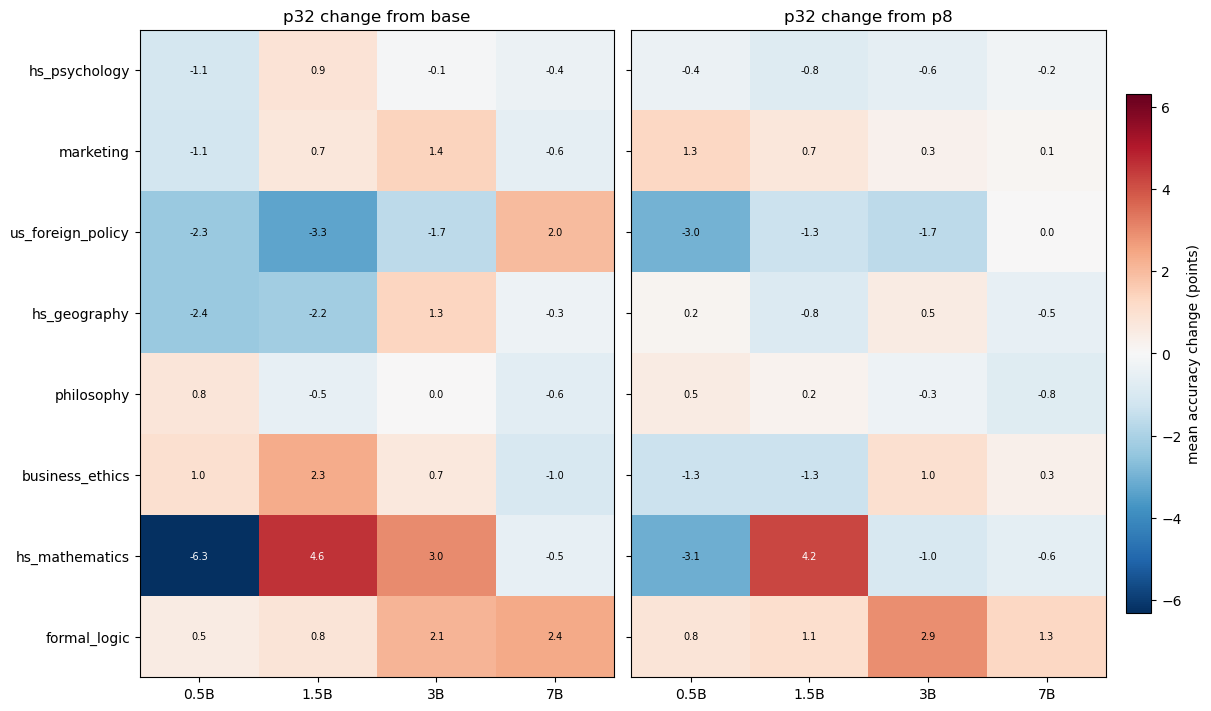

,scale,contrast,subject,tier,delta_mean,delta_min,delta_max
6,0.5B,base_to_p32,high_school_mathematics,hard,-0.0630,-0.0815,-0.0407
3,0.5B,base_to_p32,high_school_geography,medium,-0.0236,-0.0303,-0.0152
2,0.5B,base_to_p32,us_foreign_policy,easy,-0.0233,-0.0500,-0.0100
1,0.5B,base_to_p32,marketing,easy,-0.0114,-0.0214,-0.0043
0,0.5B,base_to_p32,high_school_psychology,easy,-0.0110,-0.0165,-0.0055
...,...,...,...,...,...,...,...
56,7B,p8_to_p32,high_school_psychology,easy,-0.0024,-0.0037,-0.0018
58,7B,p8_to_p32,us_foreign_policy,easy,0.0000,0.0000,0.0000
57,7B,p8_to_p32,marketing,easy,0.0014,0.0000,0.0043
61,7B,p8_to_p32,business_ethics,medium,0.0033,-0.0100,0.0300


In [16]:
subjects = [subject for tier in ("easy", "medium", "hard") for subject in TIERS[tier]]
subject_rows = []
for scale in SCALES:
    for contrast, (before_name, after_name) in contrasts.items():
        for seed in SEEDS:
            before_rows = data[scale]["base"] if before_name == "base" else data[scale][before_name][seed]
            after_rows = data[scale][after_name][seed]
            for subject in subjects:
                before = [row for row in before_rows if row["subject"] == subject]
                after = [row for row in after_rows if row["subject"] == subject]
                subject_rows.append({
                    "scale": scale,
                    "contrast": contrast,
                    "seed": seed,
                    "subject": subject,
                    "tier": TIER[subject],
                    "n_items": len(before),
                    "delta": accuracy(after) - accuracy(before),
                })

subject_df = pd.DataFrame(subject_rows)
subject_summary = (subject_df.groupby(["scale", "contrast", "subject", "tier"], sort=False)
                   .agg(delta_mean=("delta", "mean"), delta_min=("delta", "min"),
                        delta_max=("delta", "max"))
                   .reset_index())
subject_summary.to_csv(FIG / "039_1_subject_changes.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True, layout="constrained")
labels = [subject.replace("high_school_", "hs_") for subject in subjects]
matrices = []
for contrast in contrasts:
    matrix = (subject_summary[subject_summary.contrast == contrast]
              .pivot(index="subject", columns="scale", values="delta_mean")
              .reindex(index=subjects, columns=SCALES).mul(100))
    matrices.append(matrix)
limit = max(abs(matrix.to_numpy()).max() for matrix in matrices)
for ax, matrix, title in zip(axes, matrices, ("p32 change from base", "p32 change from p8")):
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(len(SCALES)))
    ax.set_xticklabels(SCALES)
    ax.set_yticks(range(len(subjects)))
    ax.set_yticklabels(labels)
    ax.set_title(title)
    for row in range(len(subjects)):
        for col in range(len(SCALES)):
            color = heatmap_text_color(image, matrix.iloc[row, col])
            ax.text(col, row, f"{matrix.iloc[row, col]:.1f}", ha="center", va="center", fontsize=7, color=color)
fig.colorbar(image, ax=axes.ravel().tolist(), label="mean accuracy change (points)", shrink=0.8, pad=0.02)
save(fig, "fig02_subject_changes")
plt.show()

display(subject_summary.sort_values(["scale", "contrast", "delta_mean"]).round(4))


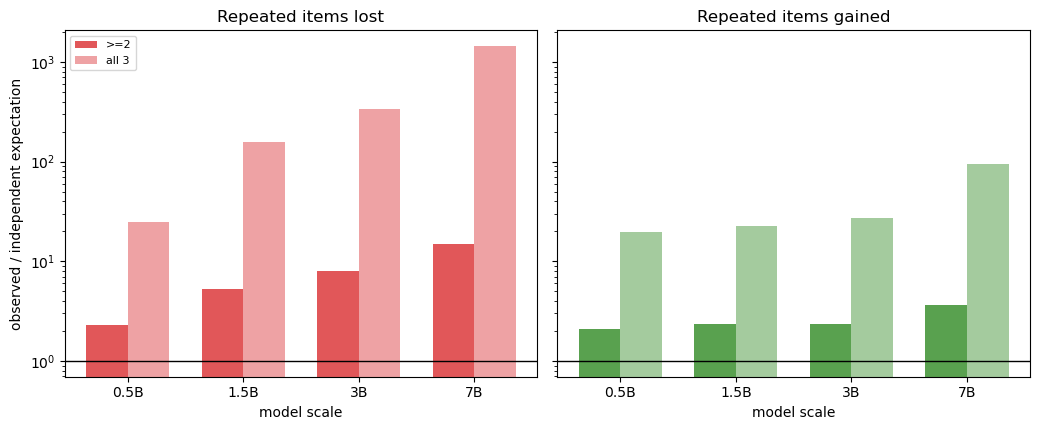

,scale,change,threshold,observed,independent_expected,ratio
0,0.5B,lost,>=2,158,69.35,2.28
1,0.5B,lost,all 3,99,4.00,24.74
2,0.5B,gained,>=2,128,61.55,2.08
3,0.5B,gained,all 3,76,3.89,19.55
4,1.5B,lost,>=2,81,15.29,5.30
5,1.5B,lost,all 3,54,0.34,158.90
6,1.5B,gained,>=2,99,42.35,2.34
7,1.5B,gained,all 3,59,2.62,22.55
8,3B,lost,>=2,56,6.94,8.07
9,3B,lost,all 3,33,0.10,338.27


In [17]:
def expected_counts(n_items, set_sizes):
    probabilities = [size / n_items for size in set_sizes]
    values = []
    for count in range(4):
        expected = 0.0
        for chosen in itertools.combinations(range(3), count):
            chosen = set(chosen)
            probability = np.prod([p if i in chosen else 1 - p
                                   for i, p in enumerate(probabilities)])
            expected += n_items * probability
        values.append(expected)
    return values


def recurrence(sets, eligible):
    return Counter(sum(i in values for values in sets) for i in eligible)


recurrence_rows = []
recurrence_plot_rows = []
for scale in SCALES:
    base_rows = data[scale]["base"]
    loss_sets = []
    gain_sets = []
    for seed in SEEDS:
        p32_rows = data[scale]["p32"][seed]
        loss_sets.append({i for i, (a, b) in enumerate(zip(base_rows, p32_rows))
                          if a["correct"] and not b["correct"]})
        gain_sets.append({i for i, (a, b) in enumerate(zip(base_rows, p32_rows))
                          if not a["correct"] and b["correct"]})

    base_correct = [i for i, row in enumerate(base_rows) if row["correct"]]
    base_wrong = [i for i, row in enumerate(base_rows) if not row["correct"]]
    values = (
        ("lost", loss_sets, base_correct),
        ("gained", gain_sets, base_wrong),
    )
    for change, sets, eligible in values:
        observed = recurrence(sets, eligible)
        expected = expected_counts(len(eligible), [len(items) for items in sets])
        for count in range(4):
            recurrence_rows.append({
                "scale": scale,
                "change": change,
                "seeds": count,
                "observed": observed[count],
                "independent_expected": expected[count],
            })
        for threshold in (2, 3):
            observed_total = sum(observed[count] for count in range(threshold, 4))
            expected_total = sum(expected[count] for count in range(threshold, 4))
            recurrence_plot_rows.append({
                "scale": scale,
                "change": change,
                "threshold": f">={threshold}" if threshold == 2 else "all 3",
                "observed": observed_total,
                "independent_expected": expected_total,
                "ratio": observed_total / expected_total,
            })

recurrence_df = pd.DataFrame(recurrence_rows)
recurrence_plot_df = pd.DataFrame(recurrence_plot_rows)
recurrence_df.to_csv(FIG / "039_1_item_recurrence.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharey=True)
x = np.arange(len(SCALES))
for ax, change, color in zip(axes, ("lost", "gained"), ("#E15759", "#59A14F")):
    part = recurrence_plot_df[recurrence_plot_df.change == change]
    for offset, threshold, alpha in ((-0.18, ">=2", 1.0), (0.18, "all 3", 0.55)):
        rows = part[part.threshold == threshold].set_index("scale").reindex(SCALES)
        ax.bar(x + offset, rows.ratio, width=0.36, color=color, alpha=alpha, label=threshold)
    ax.axhline(1, color="black", lw=1)
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(SCALES)
    ax.set_xlabel("model scale")
    ax.set_title(f"Repeated items {change}")
axes[0].set_ylabel("observed / independent expectation")
axes[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "fig03_item_recurrence")
plt.show()

display(recurrence_plot_df.round(2))


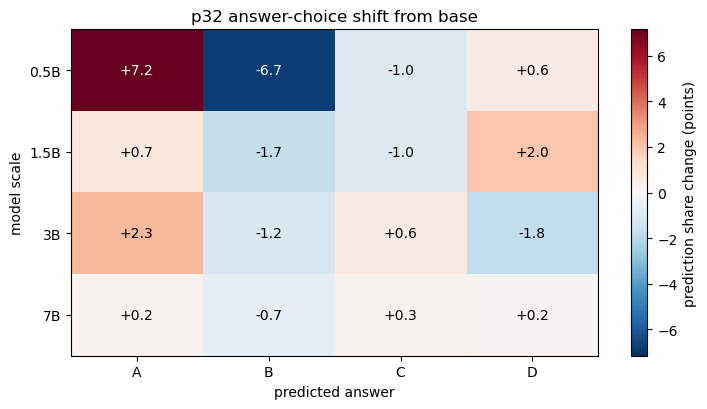

,scale,choice,base,p32_mean,delta
0,0.5B,A,0.2081,0.2797,0.0717
1,0.5B,B,0.2803,0.2128,-0.0674
2,0.5B,C,0.2670,0.2569,-0.0101
3,0.5B,D,0.2447,0.2505,0.0058
4,1.5B,A,0.1996,0.2070,0.0074
5,1.5B,B,0.2824,0.2654,-0.0170
6,1.5B,C,0.2707,0.2606,-0.0101
7,1.5B,D,0.2473,0.2670,0.0196
8,3B,A,0.2208,0.2438,0.0230
9,3B,B,0.2696,0.2580,-0.0117


scale  lost_seeds  gained_seeds
0.5B   0           2               52
                   3               76
       2           0               59
       3           0               99
1.5B   0           2               40
                   3               59
       2           0               27
       3           0               54
3B     0           2               25
                   3               43
       2           0               23
       3           0               33
7B     0           2                7
                   3               15
       2           0                9
       3           0               20
Name: items, dtype: int64

In [18]:
repeated_rows = []
choice_rows = []
for scale in SCALES:
    base_rows = data[scale]["base"]
    loss_sets = []
    gain_sets = []
    for seed in SEEDS:
        p32_rows = data[scale]["p32"][seed]
        loss_sets.append({i for i, (a, b) in enumerate(zip(base_rows, p32_rows))
                          if a["correct"] and not b["correct"]})
        gain_sets.append({i for i, (a, b) in enumerate(zip(base_rows, p32_rows))
                          if not a["correct"] and b["correct"]})

    positions = Counter()
    for i, base_row in enumerate(base_rows):
        lost_count = sum(i in values for values in loss_sets)
        gained_count = sum(i in values for values in gain_sets)
        within_subject = positions[base_row["subject"]]
        positions[base_row["subject"]] += 1
        if lost_count >= 2 or gained_count >= 2:
            repeated_rows.append({
                "scale": scale,
                "item": f"{base_row['subject']}:{within_subject:03d}",
                "subject": base_row["subject"],
                "tier": TIER[base_row["subject"]],
                "gold": base_row["gold"],
                "base_pred": base_row["pred"],
                "lost_seeds": lost_count,
                "gained_seeds": gained_count,
                "p32_preds": " / ".join(data[scale]["p32"][seed][i]["pred"] for seed in SEEDS),
            })

    for choice in "ABCD":
        base_share = np.mean([row["pred"] == choice for row in base_rows])
        p32_shares = [np.mean([row["pred"] == choice for row in data[scale]["p32"][seed]])
                      for seed in SEEDS]
        choice_rows.append({
            "scale": scale,
            "choice": choice,
            "base": base_share,
            "p32_mean": np.mean(p32_shares),
            "delta": np.mean(p32_shares) - base_share,
        })

repeated_df = pd.DataFrame(repeated_rows).sort_values(
    ["scale", "lost_seeds", "gained_seeds", "subject", "item"],
    ascending=[True, False, False, True, True])
repeated_df.to_csv(FIG / "039_1_repeated_items.csv", index=False)
choice_df = pd.DataFrame(choice_rows)

matrix = choice_df.pivot(index="scale", columns="choice", values="delta").reindex(SCALES).mul(100)
limit = abs(matrix.to_numpy()).max()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
image = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(4))
ax.set_xticklabels(list("ABCD"))
ax.set_yticks(range(len(SCALES)))
ax.set_yticklabels(SCALES)
ax.set_xlabel("predicted answer")
ax.set_ylabel("model scale")
ax.set_title("p32 answer-choice shift from base")
for row in range(len(SCALES)):
    for col in range(4):
        color = heatmap_text_color(image, matrix.iloc[row, col])
        ax.text(col, row, f"{matrix.iloc[row, col]:+.1f}", ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, label="prediction share change (points)")
fig.tight_layout()
save(fig, "fig04_choice_shift")
plt.show()

display(choice_df.round(4))
display(repeated_df.groupby(["scale", "lost_seeds", "gained_seeds"]).size().rename("items"))


## Cross-referenced conclusion

The erosion seen at 0.5B does not repeat across all scales. From base to p32, the mean overall
changes are -1.52, +0.67, +0.81 and -0.18 points from 0.5B to 7B. The hard tier changes are
-4.12, +3.37, +2.69 and +0.42 points. This makes the earlier 0.5B result scale specific rather
than a general effect of heavy MC-SFT.

Cleaner p8-to-p32 comparison gives the same reading. Its mean overall changes are -0.46,
+0.34, -0.11 and -0.21 points, while the hard tier changes are -1.85, +3.20, +0.25 and 0.00.
None of the seedwise McNemar tests remains significant after Holm correction, so smaller
differences should not be overstated.

At 0.5B, high school mathematics still carries the largest loss and the large shift towards A
and away from B is not repeated at the other scales. Item changes are more repeatable than the
independent reference at every scale, even when gains and losses cancel in the headline accuracy.
This means the models move on a stable subset of items, but only the smallest model shows clear
net erosion.

This is a retrospective analysis of stored probe predictions. Shows structured probe movement,
not direct proof that factual knowledge was forgotten. Each exposure also used its own linear
learning rate schedule, so the curve remains a method as practised budget comparison.
